TensorFlow: 2.21.0
x_train: (1000, 29, 50)  y_train: (1000, 29, 50)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 29, 256)        │       183,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 29, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 29, 50)         │        12,850 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 590,386 (2.25 MB)

 Trainable params: 590,386 (2.25 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 95ms/step - accuracy: 0.1083 - loss: 3.8840 - val_accuracy: 0.1674 - val_loss: 3.8424
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.1302 - loss: 3.7698 - val_accuracy: 0.0976 - val_loss: 3.6604
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.1185 - loss: 3.5197 - val_accuracy: 0.1360 - val_loss: 3.4001
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.1578 - loss: 3.2351 - val_accuracy: 0.1724 - val_loss: 3.1217
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.2097 - loss: 2.8858 - val_accuracy: 0.2336 - val_loss: 2.7429
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.2750 - loss: 2.5026 - val_accuracy: 0.3045 - val_loss: 2.3696
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.3459 - loss: 2.1244 - val_accuracy: 0.3838 - val_loss: 1.9947
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4271 - loss: 1.7621 - val_accuracy: 0.4650 - 

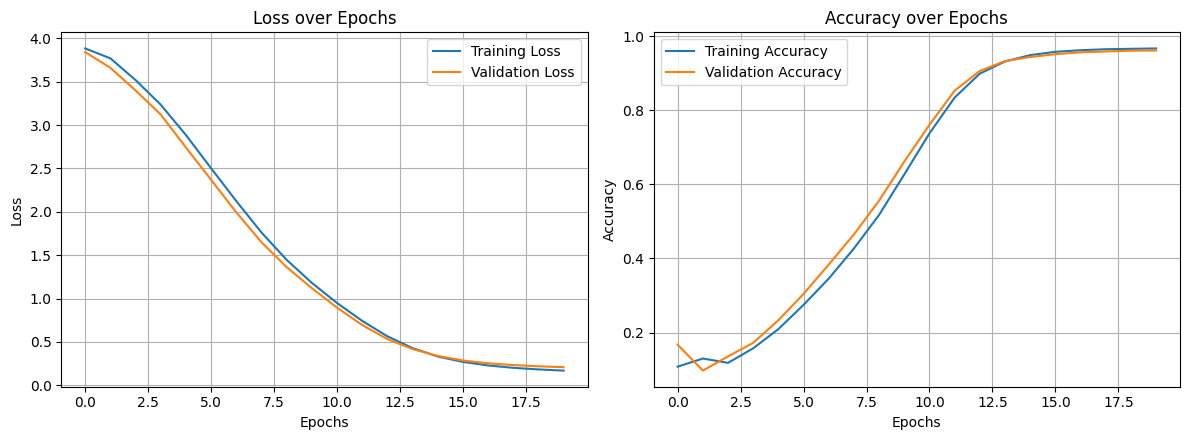

Generated: [28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28]


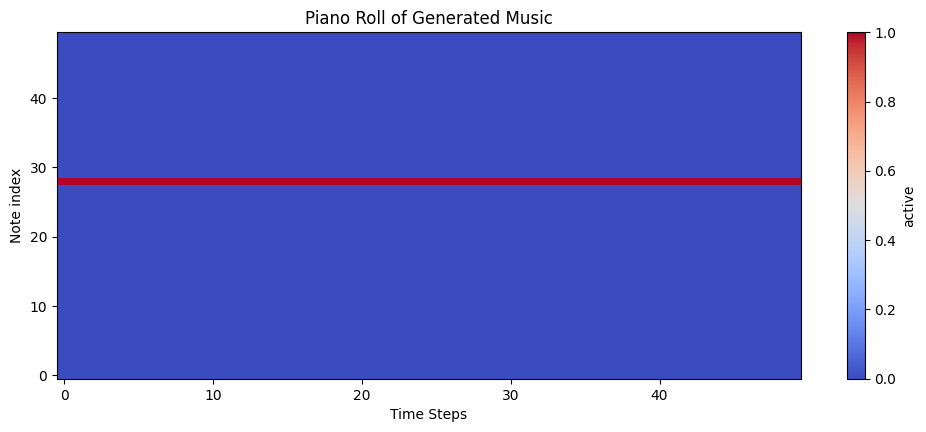

Selected sound: Omni Reverse


Saved audio file: generated_music_omni_reverse.wav
Preview: Piano


Preview: Guitar


Preview: Violin


Preview: Flute


Preview: Omni Reverse


In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

np.random.seed(42); tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)
num_notes       = 50
sequence_length = 30
num_sequences   = 1000

data = np.random.randint(0, num_notes, size=(num_sequences, sequence_length))


x_train = data[:, :-1]
y_train = data[:, 1:]


NUM_CLASSES = num_notes
x_train = to_categorical(x_train, num_classes=NUM_CLASSES)
y_train = to_categorical(y_train, num_classes=NUM_CLASSES)

print("x_train:", x_train.shape, " y_train:", y_train.shape)
model = models.Sequential()
model.add(layers.Input(shape=(sequence_length-1, num_notes)))


model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))


model.add(layers.Bidirectional(layers.LSTM(128, return_sequences=True)))


model.add(layers.TimeDistributed(layers.Dense(num_notes, activation='softmax')))

model.summary()

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])


history = model.fit(x_train, y_train,
                    epochs=20,
                    batch_size=64,
                    validation_split=0.2)
plt.figure(figsize=(12,4.5))

plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Loss'); plt.legend(); plt.grid()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs'); plt.xlabel('Epochs'); plt.ylabel('Accuracy'); plt.legend(); plt.grid()

plt.tight_layout(); plt.show()
def generate_music(model, start_sequence, num_generated_notes=50):
    generated = []
    current_sequence = start_sequence.copy()

    for _ in range(num_generated_notes):
        pred = model.predict(current_sequence, verbose=0)


        next_note = np.argmax(pred[:, -1, :], axis=-1)
        generated.append(int(next_note[0]))


        oh = to_categorical(next_note, num_classes=num_notes).reshape(1, 1, num_notes)
        current_sequence = np.concatenate(
            [current_sequence[:, 1:, :], oh], axis=1
        )

    return generated


start = np.random.randint(0, num_notes, size=(1, sequence_length-1))
start = to_categorical(start, num_classes=num_notes)

generated_music = generate_music(model, start, num_generated_notes=50)
print("Generated:", generated_music)
piano_roll = np.zeros((num_notes, len(generated_music)))
for t, note in enumerate(generated_music):
    piano_roll[note, t] = 1

plt.figure(figsize=(12,4.5))
plt.imshow(piano_roll, aspect='auto', cmap='coolwarm', origin='lower', interpolation='nearest')
plt.colorbar(label='active'); plt.title('Piano Roll of Generated Music')
plt.xlabel('Time Steps'); plt.ylabel('Note index'); plt.show()
instrument = "Omni Reverse"

import numpy as np
from IPython.display import Audio, display
from scipy.io.wavfile import write

SAMPLE_RATE = 22050
NOTE_DURATION = 0.30
NOTE_GAP = 0.025

INSTRUMENT_HARMONICS = {
    "Piano": [1.00, 0.48, 0.24, 0.12, 0.06],
    "Guitar": [1.00, 0.65, 0.35, 0.18, 0.08],
    "Violin": [1.00, 0.70, 0.50, 0.32, 0.18],
    "Flute": [1.00, 0.12, 0.035, 0.01, 0.00]
}

AVAILABLE_INSTRUMENTS = [
    "Piano", "Guitar", "Violin", "Flute", "Omni Reverse"
]

def synthesize_note(midi_note, instrument_name, duration=NOTE_DURATION,
                    sample_rate=SAMPLE_RATE):
    if instrument_name not in INSTRUMENT_HARMONICS:
        raise ValueError("Choose Piano, Guitar, Violin, Flute, or Omni Reverse.")

    n_samples = int(duration * sample_rate)
    t = np.arange(n_samples) / sample_rate
    frequency = 440.0 * (2.0 ** ((midi_note - 69) / 12.0))

    waveform = np.zeros(n_samples, dtype=np.float64)
    for harmonic_number, strength in enumerate(
        INSTRUMENT_HARMONICS[instrument_name], start=1
    ):
        waveform += strength * np.sin(
            2 * np.pi * frequency * harmonic_number * t
        )

    if instrument_name == "Piano":
        envelope = np.exp(-5.0 * t)
    elif instrument_name == "Guitar":
        envelope = np.exp(-7.0 * t)
    elif instrument_name == "Violin":
        attack = min(0.08, duration / 3)
        envelope = np.ones_like(t)
        envelope *= np.clip(t / max(attack, 1e-4), 0, 1)
        envelope *= np.exp(-0.8 * t)
    else:
        attack = min(0.06, duration / 3)
        envelope = np.ones_like(t)
        envelope *= np.clip(t / max(attack, 1e-4), 0, 1)
        envelope *= np.exp(-1.8 * t)

    waveform *= envelope
    peak = np.max(np.abs(waveform))
    if peak > 0:
        waveform = waveform / peak
    return waveform

def create_omni_reverse_audio(note_ids, tempo_bpm=120):
    if len(note_ids) == 0:
        return np.zeros(1, dtype=np.float32)

    beep_duration = 0.16
    pause_duration = 0.12
    sample_count = int(beep_duration * SAMPLE_RATE)
    t = np.arange(sample_count) / SAMPLE_RATE
    parts = []

    for index, note_id in enumerate(note_ids):
        base_frequency = 720 if index % 2 == 0 else 610
        pitch_adjustment = (int(note_id) % 5) * 12
        frequency = base_frequency + pitch_adjustment
        tone = (
            np.sin(2 * np.pi * frequency * t)
            + 0.25 * np.sin(2 * np.pi * frequency * 2 * t)
        )
        fade = np.minimum(1.0, t / 0.012)
        fade *= np.minimum(1.0, (beep_duration - t) / 0.018)
        tone = tone * fade
        parts.append(tone)
        parts.append(np.zeros(int(pause_duration * SAMPLE_RATE)))

    audio = np.concatenate(parts)
    peak = np.max(np.abs(audio))
    if peak > 0:
        audio = 0.85 * audio / peak
    return audio.astype(np.float32)

def create_melody_audio(note_ids, instrument_name, tempo_bpm=120):
    if instrument_name == "Omni Reverse":
        return create_omni_reverse_audio(note_ids, tempo_bpm)

    note_duration = 60.0 / tempo_bpm / 2.0
    gap_samples = int(NOTE_GAP * SAMPLE_RATE)
    silence = np.zeros(gap_samples, dtype=np.float64)
    audio_parts = []

    for note_id in note_ids:
        midi_pitch = 48 + int(note_id)
        audio_parts.append(
            synthesize_note(midi_pitch, instrument_name, duration=note_duration)
        )
        audio_parts.append(silence)

    if not audio_parts:
        return np.zeros(1, dtype=np.float32)

    audio = np.concatenate(audio_parts)
    peak = np.max(np.abs(audio))
    if peak > 0:
        audio = 0.90 * audio / peak
    return audio.astype(np.float32)

music_audio = create_melody_audio(generated_music, instrument)
print("Selected sound:", instrument)
display(Audio(music_audio, rate=SAMPLE_RATE))

wav_audio = np.int16(np.clip(music_audio, -1, 1) * 32767)
wav_filename = f"generated_music_{instrument.lower().replace(' ', '_')}.wav"
write(wav_filename, SAMPLE_RATE, wav_audio)
print("Saved audio file:", wav_filename)

for instrument_option in AVAILABLE_INSTRUMENTS:
    preview = create_melody_audio(generated_music, instrument_option)
    print("Preview:", instrument_option)
    display(Audio(preview, rate=SAMPLE_RATE))
